# SQDMetal Xmon capacitance-simulation example — cross transmon with an open-ended coupled readout (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/Palace_Capacitance_Xmon_Gmsh.ipynb`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/xmon_cap_sim.md`): a Quantum
Metal design meshed with Gmsh for a Palace capacitance run on silicon (280 µm); it stores no outputs. One grounded
`TransmonCross` with two claws (readout east, bus west). The readout claw runs a 3.7 mm `RouteMeander` to an
`OpenToGround` 40 µm below a straight transmission line between two small `LaunchpadWirebond`s; the meander's
300 µm start straight runs parallel to the line, so the line couples through an open-ended coupled section.

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | Metal chip 4.6 × 2.4 mm centred on (0, −1) mm | the 7.5 × 7.5 mm Quantcore die with its frame, device ID "SQD-XCS"; the source area in its centre (Designer = source + (2300, 2200) µm before centring) |
| pads | two `LaunchpadWirebond`s at x = ±2 mm (1465 µm from our die edges) | the same launchpads **on the die edges**: outer etch 100 µm (`frame.pad_edge`) from the west / east edge (PDK pad rule); the line between them is 2.7 mm longer |
| substrate | silicon, 280 µm | sapphire 650 µm, εr 10.25 |
| junctions | none (a capacitance-only run) | the Quantcore trilayer junction at the PDK nominal: 0.5 × 0.6 µm, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF |
| cheese | none (`cap_sim.add_ground_plane()` without holes; the spec: "no fill") | the PDK band (chip `cheese` `"auto"`, at least 4 µm clear of 3/0) |
| components | `TransmonCross` (`bus_01` claw 95 µm), `RouteMeander` 3.7 mm, `RoutePathfinder`, `OpenToGround` | kept through the `metal:` wrapper with the source options; the meander + `OpenToGround` are one qcc open hanger route |
| placement | — | centred in the die (the source content sat 214 µm above the centre; shifted) |

**Substituted:** the `OpenToGround` + `RouteMeander` pair is one qcc route ending in an open hanger (`end="open"`,
6 µm open gap): electrically the same λ/2-type line, open at the coupled end and capacitive at the claw; the
meander is KQC's on the leg between the claw and the line (r = 99.9 µm, the source fillet). The `TL`
`RoutePathfinder` is a straight qcc route. **Kept:** the `bus_01` claw is left open, as in the source.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; set it to `True` to solve the jobs in a new batch
AEDT 2024 R1 (if one is installed). `FULL_FAB = False` skips the fab-only corner rounding in the mask step
(`qcc mask` writes the complete file). Step snapshots go to `build/snapshots/` (not kept in the repo); the final
ones next to the notebook.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "xmon_cap_sim"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 2300, 2200                              # Metal's chip is centred on (0, -1) mm

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** The source sets no junction (a capacitance run); the rebuild draws the PDK
nominal trilayer junction in the cross (`trilayer_junction("metal:TransmonCross")`: `junction_type` for the cell,
L_J / C_J for the LOM). Expected f_q ≈ 5.8–6.0 GHz (the pre-rebuild build assumed 12 nH and gave 4.6 GHz).

In [4]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonCross")     # nominal: 0.5 × 0.6 µm, R_n 45 kΩ
print("cell parameters:", JJ_PARAMS, "| LOM junction:", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Junction'} | LOM junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so the source's 4.6 × 2.4 mm area
sits in its middle (every source position + (2300, 2200) µm). The PDK frame: L dicing markers (1000/0), 3 × 3
alignment grids (1001/0), the chip boundary (100/0), the device ID on a free edge. The chip `cheese` stays
`"auto"`: the source has no cheese, so the PDK band is drawn.

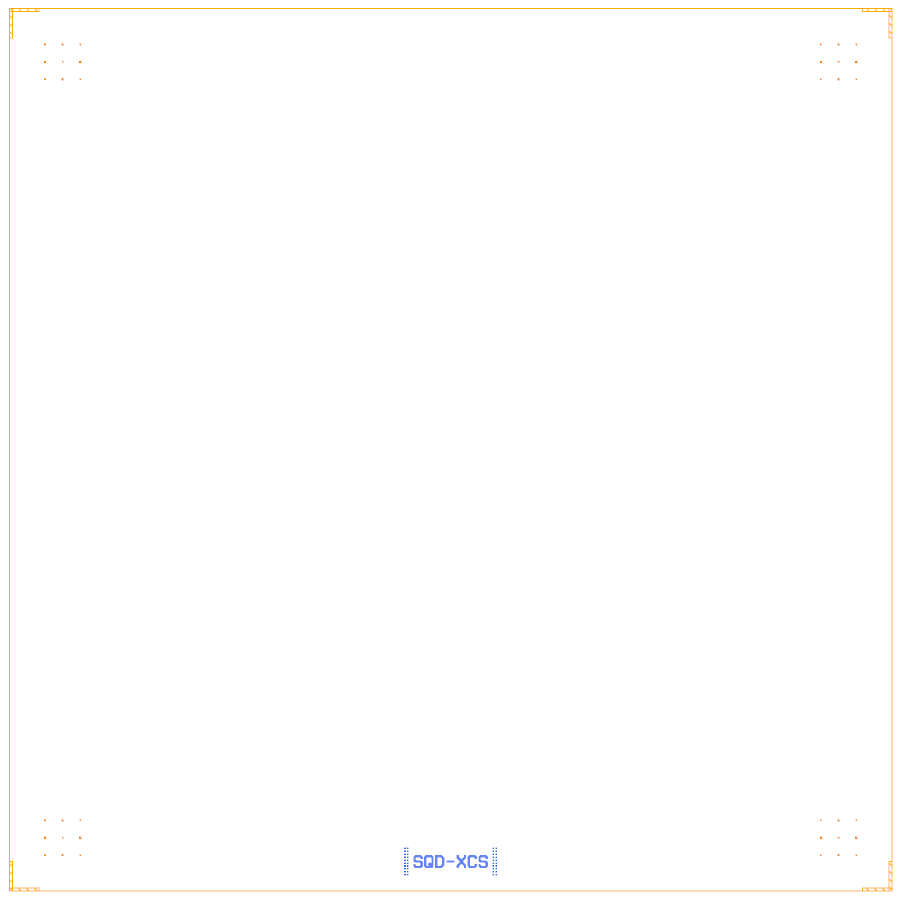

In [5]:
d = Designer("xmon_cap_sim", box=(-1450, -2550, 6050, 4950), chip={"name_chip": "SQD-XCS"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(900, 900), width=360);

## 4 · Pads and the pad rule

**PDK rule:** a bond pad's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. The source's
two `LaunchpadWirebond`s (103 × 103 µm pad, 60 µm gap, 30 µm lead) sat at x = ±2 mm, 1465 µm inside our die; here
each is added at the source's y with `edge="w"` / `edge="e"`, which slides it perpendicular to that edge until
its etch is 100 µm from it (each pad moves 1365 µm out). The table measures the result.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

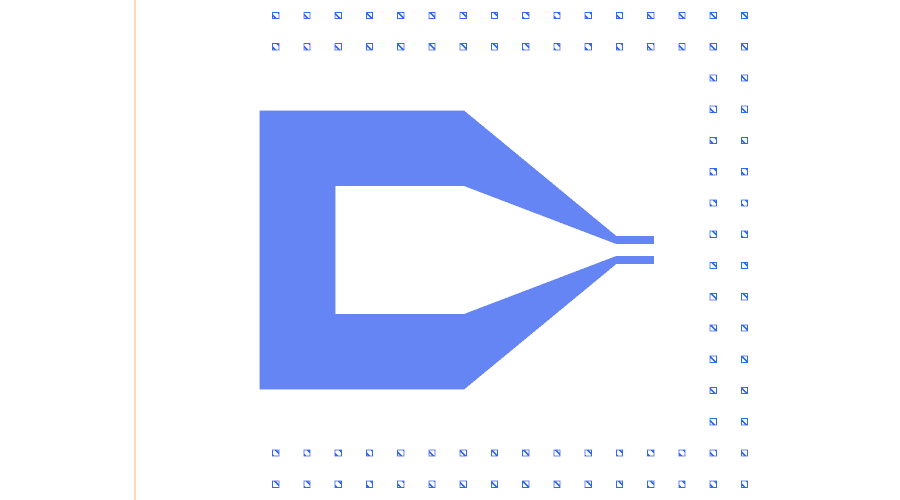

In [6]:
LP = dict(lead_length=30, pad_height=103, pad_width=103, pad_gap=60)
with d.batch():
    lp1 = d.add("LP1", "metal:LaunchpadWirebond", at=(X0 - 2000, Y0), rot=0, edge="w", **LP)
    lp2 = d.add("LP2", "metal:LaunchpadWirebond", at=(X0 + 2000, Y0), rot=180, edge="e", **LP)
rebuild(d)
display(Markdown(pads_md(d)))
x, y = port_xy(d, "LP1.tie")
snap(d, STEPS / "2_pad.png", box=(-1460, y - 200, x + 100, y + 200), size=(900, 500), width=420);

## 5 · Components

The Quantum Metal `TransmonCross` through the `metal:` wrapper (Metal options as cell parameters; bare numbers on
length options are µm), with the source's connection pads: `readout` at 0° and `bus_01` at 180° with a 95 µm
claw; the other options are Metal's defaults (arms 200 µm long, 20 µm wide, 20 µm gap). Ports: the claws
`readout` and `bus_01`, and the junction attachment points `squid_a` / `squid_b`.

<metal:TransmonCross Q1 ports=['bus_01', 'readout', 'squid_a', 'squid_b']>


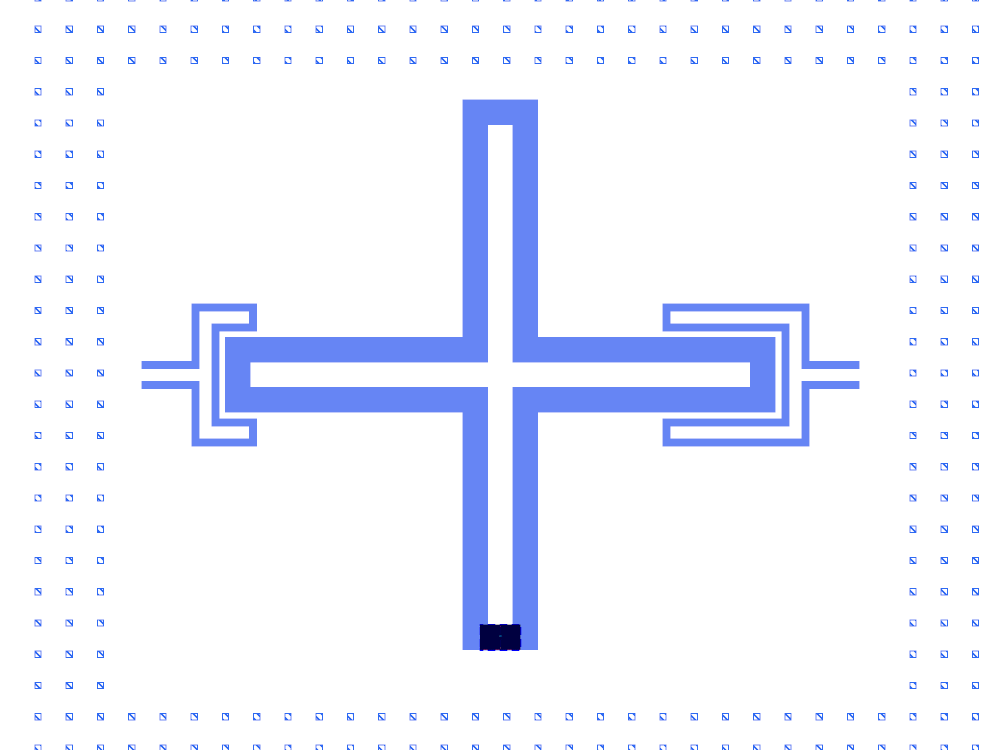

In [7]:
q1 = d.add("Q1", "metal:TransmonCross", at=(X0 + 607.5, Y0 - 1464),
           connection_pads={"bus_01": {"connector_location": "180", "claw_length": 95},
                            "readout": {"connector_location": "0"}},
           junction=JUNCTION, **JJ_PARAMS)
print(q1)
qx, qy = X0 + 607.5, Y0 - 1464
snap(d, STEPS / "3_qubit.png", box=(qx - 400, qy - 300, qx + 400, qy + 300), size=(1000, 750), width=420);

## 6 · Routes

**The line** `TL` between the two launchpads' `tie` pins (10/6 µm, straight; the source's `RoutePathfinder`).

**The readout** from the `readout` claw: west to a waypoint, then KQC's meander up to the coupled section and an
**open** hanger end 40 µm below the line (`end="open"`: 6 µm open gap; centre spacing 40 µm = 5 + 6 + 18 + 6 + 5,
so `ground_gap=18`), 3700 µm in total. `TL.hanger(near=(x, y), ...)` centres the 400 µm coupled part (the
source's 300 µm `start_straight` plus its bend) at the line point nearest (1900, y_TL) — the source's position,
independent of where the line starts, so moving the pads to the edge does not move it.

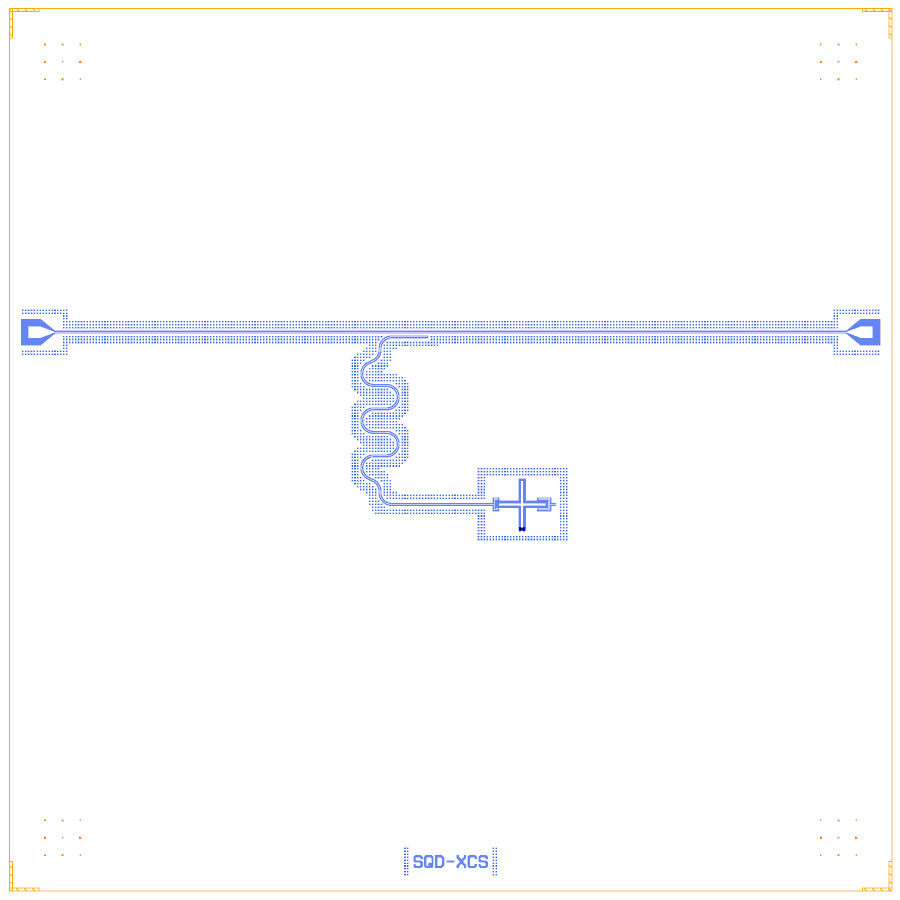

{'TL': 6670.0, 'R1': 3700.0}


In [8]:
x_open = X0 - 200                                # the OpenToGround (source x -0.2 mm)
with d.batch():
    tl = d.route("TL", lp1.tie, lp2.tie, r=90)
    d.route("R1", q1.readout, tl.hanger(near=(x_open - 200, Y0), length=400, side="right", ground_gap=18,
                                        direction="forward", end="open"),
            meander=3700, r=99.9, nodes=[(x_open - 400, Y0 - 1464)])
snap(d, STEPS / "4_routes.png", size=(900, 900), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Sim group, centring, save.** One sim group: the qubit, its readout and the line (a Q3D C-matrix — the source's
own analysis — and an eigenmode / EPR job). `center_in_die` applies the PDK placement rule: the content (the line
at y = 2200 down to the qubit at y ≈ 500) sat ≈ 214 µm above the die centre, so everything moves down by that
much (instance positions, waypoints and the hanger's `near` point; the pads stay on their edges). Then the design
is saved.

In [9]:
d.sim_group("Q1R1", ["Q1", "R1", "TL"])
DX, DY = center_in_die(d)
print("centring shift (µm):", (DX, DY))
rebuild(d)
DESIGN = d.save(OUT / "xmon_cap_sim.json")
print(d, "→", DESIGN, "| R1", round(d.result.route_lengths()["R1"], 1), "µm")

centring shift (µm): (0.0, -213.8)
<Designer xmon_cap_sim: 3 instances, 2 routes, live=False> → examples\designs\sqdmetal\xmon_cap_sim.json | R1 3700.0 µm


## 7 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here: **no errors**; three `dangling_port` warnings, the open `bus_01` claw (the source leaves it
unconnected) and the junction attachment points `squid_a` / `squid_b`. No PDK design warning is expected:
`pdk_claw` reads bare numbers on Metal length options as µm, as the qcc Metal wrapper does (`claw_length: 95` =
95 µm; the check's units were fixed on 2026-11-04, it used to read mm and flag a 95 000 µm claw), and the
95 µm claw is well inside the 200 µm arms. `pdk_report` counts only the cells that draw a junction, so it should
read "Quantcore Junction × 1" (Q1; the launchpads are not counted).

In [10]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 3 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 3 | Q1.bus_01 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` maps each component's ports onto circuit nodes. The `TransmonCross` is a grounded island (C and the
junction to ground) with one node per claw (C_g to the island, C to ground); the open `bus_01` claw stays a node
with only its capacitances (the netlist lists it as the one unconnected port). The readout between the claw and
an open end is a λ/2-type `TLres`; its open coupled section is a `HANGER` κ element to the line node, and the
launchpads are the line's two 50 Ω ports.

In [11]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1 / R1 / TL ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("Q1.", "R1", "TL")))))

**5 nodes · 10 branches · 0 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `TL` | `TL`, `LP1.pad`, `LP2.pad` |
| `Q1` | `Q1.island` |
| `Q1.bus_01` | `Q1.bus_01` |
| `Q1.readout` | `Q1.readout` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LP1` | R | `TL` – `gnd` | 50 Ω |
| `Port_LP2` | R | `TL` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 86.9 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_bus_01` | C | `Q1` – `Q1.bus_01` | 2.4 fF |
| `Cc_Q1_bus_01` | C | `Q1.bus_01` – `gnd` | 49 fF |
| `Cg_Q1_readout` | C | `Q1` – `Q1.readout` | 1.1 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 29.8 fF |
| `R1` | TLres | `Q1.readout` – `gnd` | lambda/2, 3700 µm, 17.032 GHz |
| `K_R1` | HANGER | `Q1.readout` – `TL` | κ 0.0309 MHz (L 400 µm) |

**Unconnected ports:** `Q1.bus_01`

**Q1 / R1 / TL ports → circuit nodes:**

| port | node |
|---|---|
| `Q1.bus_01` | `Q1.bus_01` |
| `Q1.readout` | `Q1.readout` |
| `Q1.squid_a` | `Q1` |
| `Q1.squid_b` | `gnd` |

## 9 · LOM simulation

QuCat normal modes of the whole circuit (frequencies, κ into the two 50 Ω launchpads, anharmonicities), then the
QuTiP-dressed values. The source states no frequencies (it extracts a capacitance matrix). Expected: f_q ≈ 6 GHz
with the nominal junction, α ≈ −180 MHz, and the open λ/2-type readout at ≈ 16 GHz (a 3.7 mm line between a
claw and an open end; on silicon too it would sit far above the qubit), with a small κ from the 400 µm open
coupled section.

In [12]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.9770 | 0 | 184.0 | J_Q1 1.00 |
| R1 | resonator | 16.1108 | 0.0247 | 0.0 | R1 1.00 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 5.7868 | – |
| `Q1.alpha_MHz` | -198.85 | – |
| `R1.chi_MHz` | -0.13702 | – |
| `R1.f_GHz` | 16.111 | – |
| `R1.kappa_MHz` | 0.024718 | – |

## 10 · FEM: send the jobs
The LOM uses analytic capacitance estimates; a finite-element job measures them. `send_fem_jobs` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, each Ansys job is solved in a **new batch,
non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [13]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · eigenmode_epr | `build/jobs/xmon_cap_sim_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · lumped · `LP1.pad`<br>3 · lumped · `LP2.pad` | `Q1.island`, `LP1.pad`, `Q1.readout` |
| Q1R1 · q3d_cmatrix | `build/jobs/xmon_cap_sim_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.readout`<br>3 · lumped · `LP1.pad`<br>4 · lumped · `LP2.pad` | `Q1.island`, `Q1.readout`, `LP1.pad` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`:
the C-matrix replaces the component estimates branch by branch (matched by net name), and the table compares the two;
`simulate(filled)` re-runs the LOM on the extracted values. Until a solve has run, the cell says which jobs are still
waiting.

In [14]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1R1 · eigenmode_epr, Q1R1 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The readout's coupling to the line is set by the coupled section: shorten it from 400 to 250 µm. The coupled-line
κ drops (roughly with the square of the coupled length) and the readout frequency barely moves (the total length
is unchanged). The waypoint before the coupled section sits at its start, so it moves with it (otherwise the
last vertical leg gets a jog shorter than two bends). Done on a copy (`design_copy`), so `xmon_cap_sim.json`
keeps the source's section.

In [15]:
d2 = design_copy(DESIGN)
end, (nx, ny) = d2["R1"].spec["to"], d2["R1"].spec["nodes"][0]
d2["R1"].set(to=dict(end, length=250), nodes=[(end["near"][0] - 250 / 2, ny)])   # waypoint at the section start
after = simulate_lom(d2.lom(), d2.design)
display(Markdown("**R1 coupled section: 400 → 250 µm**\n\n" + params_delta_md(res, after)))
display(Markdown("| mode | κ before (MHz) | κ after (MHz) |\n|---|---|---|\n" + "\n".join(
    f"| {a.label} | {a.kappa_MHz:.3g} | {b.kappa_MHz:.3g} |" for a, b in zip(res.modes, after.modes))))

**R1 coupled section: 400 → 250 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1.f_q_GHz` | 5.7868 | 5.7868 | +6.604e-10 |
| `Q1.alpha_MHz` | -198.85 | -198.85 | -4.68e-07 |
| `R1.chi_MHz` | -0.13702 | -0.19864 | -0.06162 |
| `R1.f_GHz` | 16.111 | 16.115 | +0.004276 |
| `R1.kappa_MHz` | 0.024718 | 0.0097224 | -0.015 |

| mode | κ before (MHz) | κ after (MHz) |
|---|---|---|
| Q1 | 0 | 0 |
| R1 | 0.0247 | 0.00972 |

## 13 · Build and export

**The design file.** `xmon_cap_sim.json` (saved in step 6) is the whole design:
`qcc build examples/designs/sqdmetal/xmon_cap_sim.json` rebuilds `build/xmon_cap_sim.oas` + its sidecar, and the
KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and spacer 50–53/0, and the frame (100/0, 1000/0, 1001/0).
**Cheese:** the source has none (it meshes the design for Palace, `add_ground_plane()` with no holes), so the PDK
band stands — drawn in the build (`cheese_source` `build`), at least 4 µm clear of 3/0. Corner rounding is fab-only (`FULL_FAB`);
`qcc mask examples/designs/sqdmetal/xmon_cap_sim.json` writes the complete file.

In [16]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2428 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 2421 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 2417 holes on the mask.

→ `build/xmon_cap_sim_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [17]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}
airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full chip (the launchpads on the west / east edges); the cross transmon with both claws; its trilayer junction;
the open-ended coupled section under the line; the die frame's south-west corner (dicing L on 1000/0, 3 × 3
alignment grid on 1001/0); and the qubit in the **fab view** (the mask from step 13: 1/0 with the PDK cheese band,
the 3/0 keep-out, the junction layers). In the layout snapshots the chip boundary 100/0 is drawn as an outline and
the cheese band (KQC's ground-grid layer) is visible; the fab view shows the mask itself.

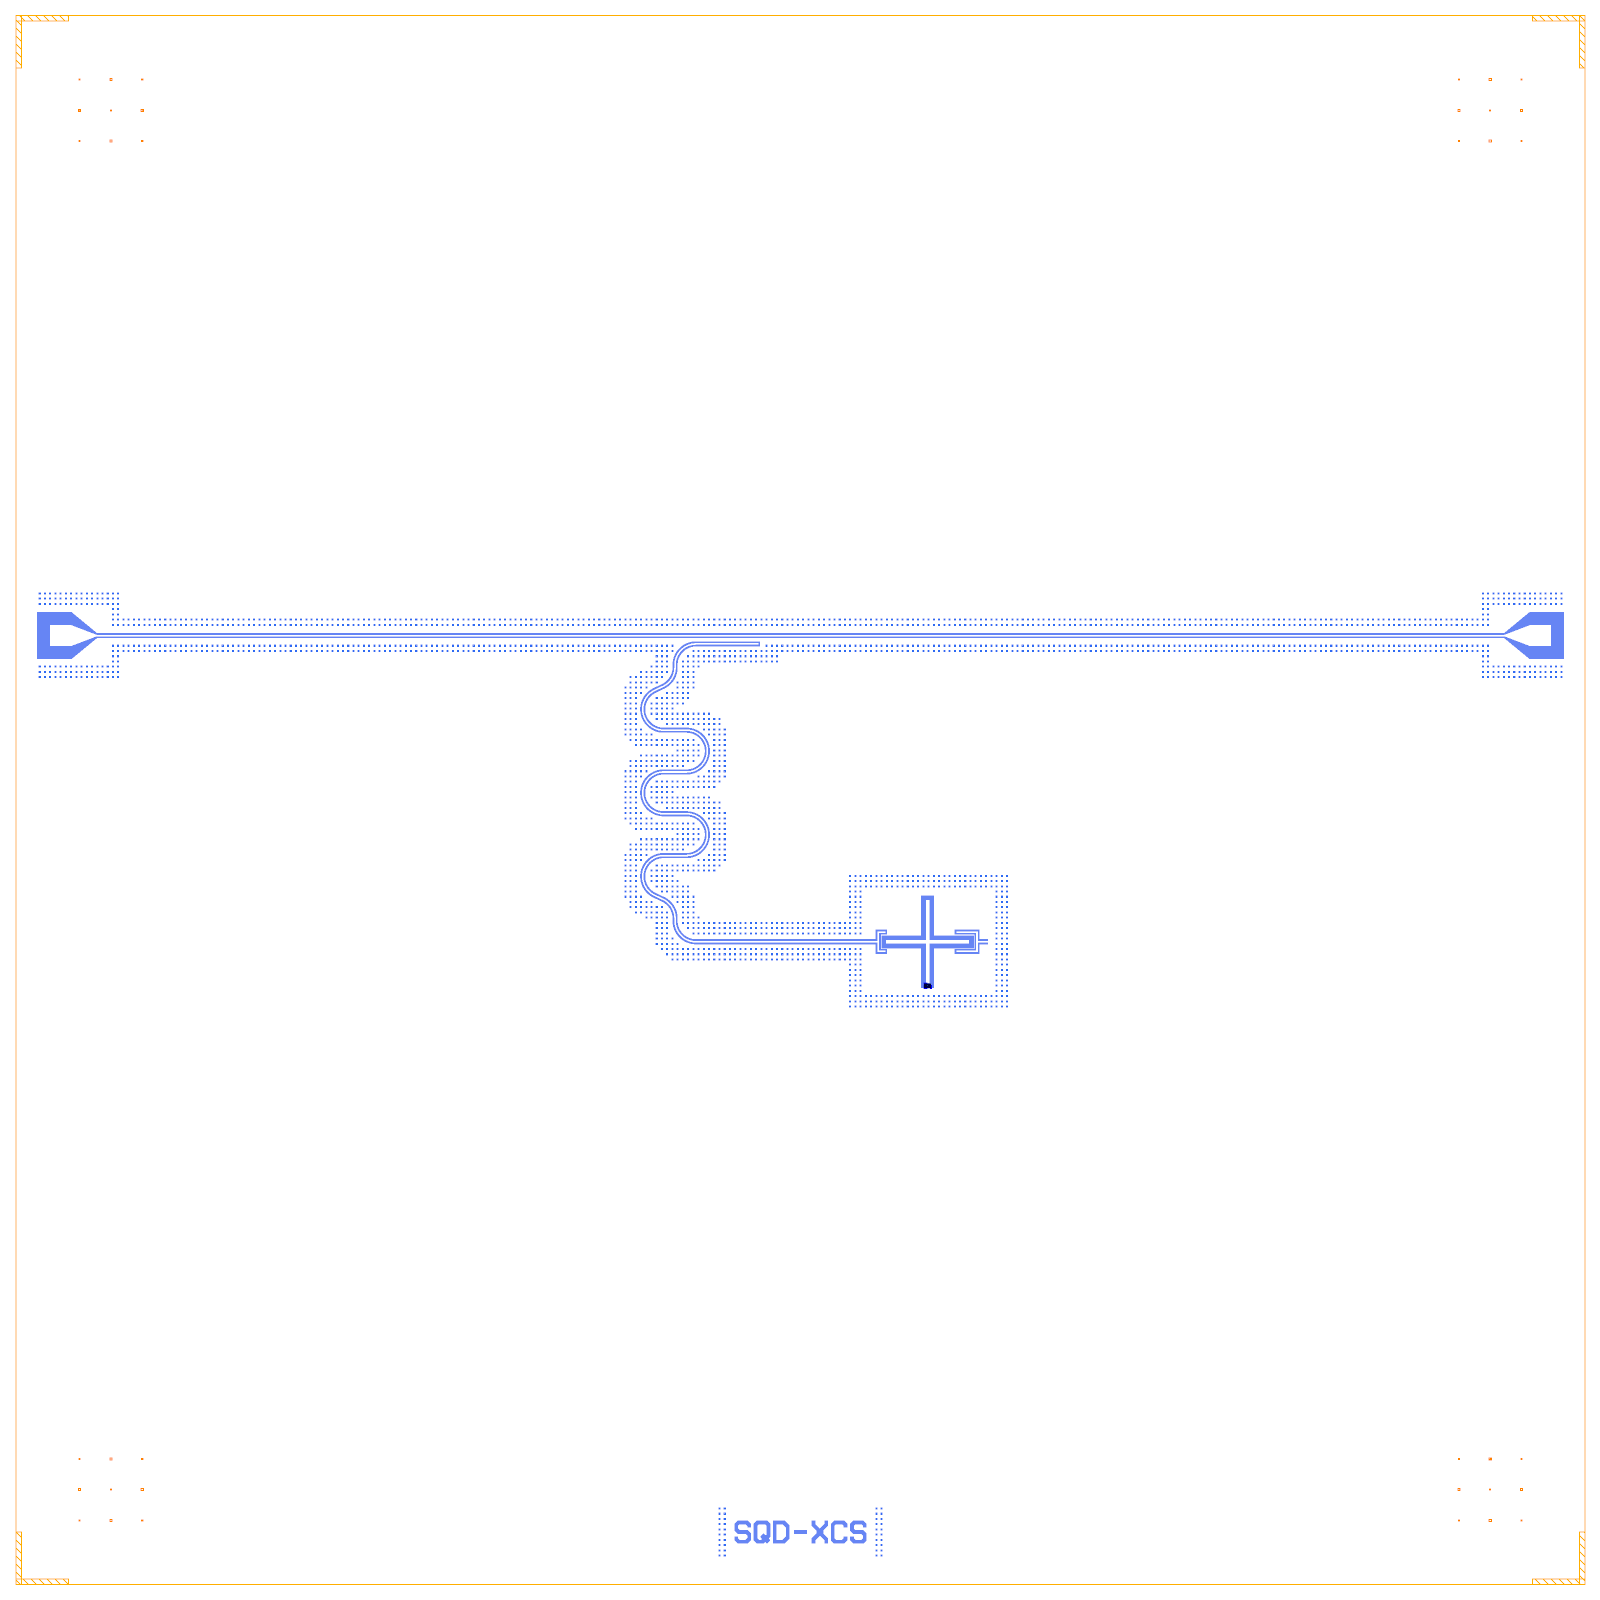

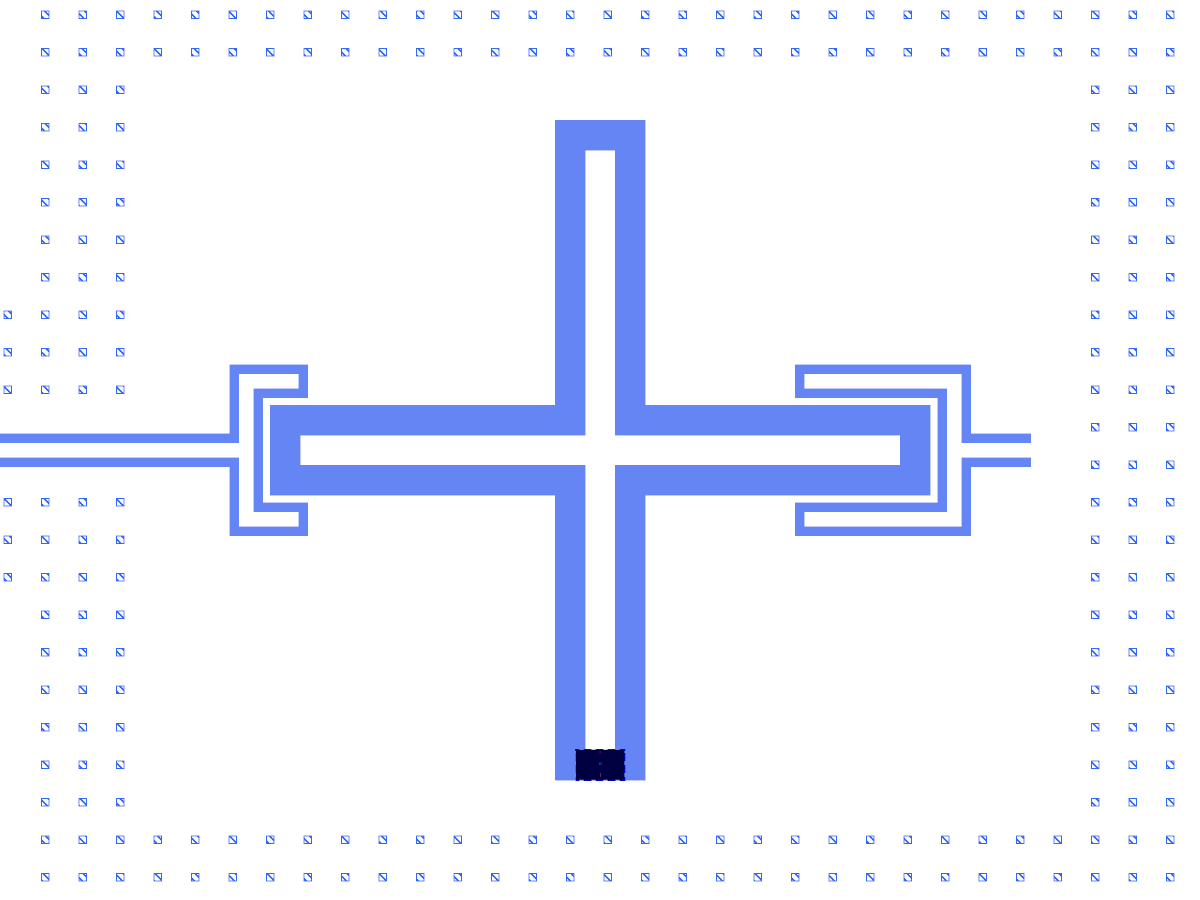

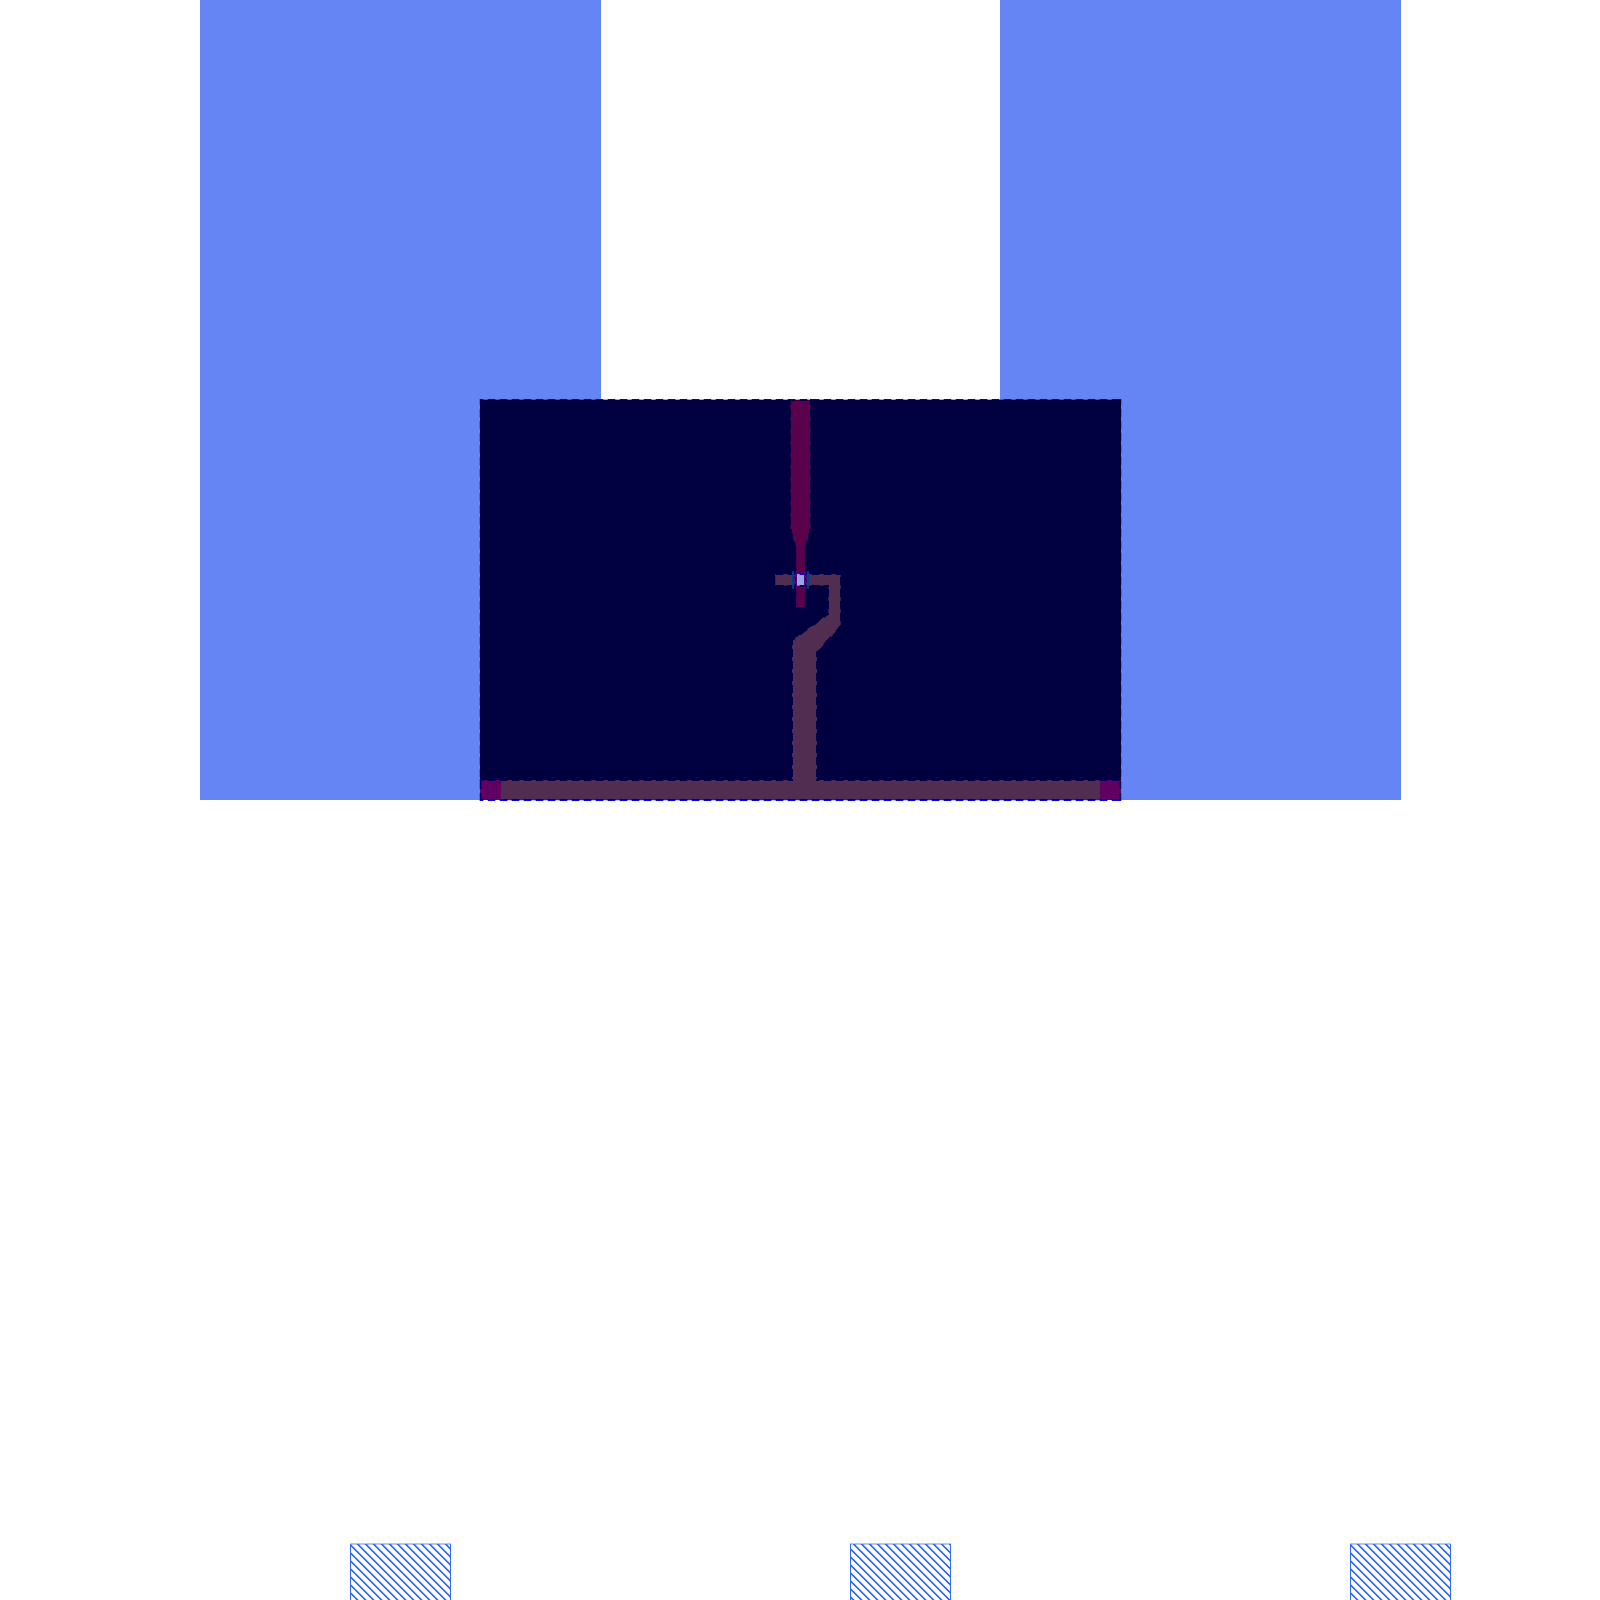

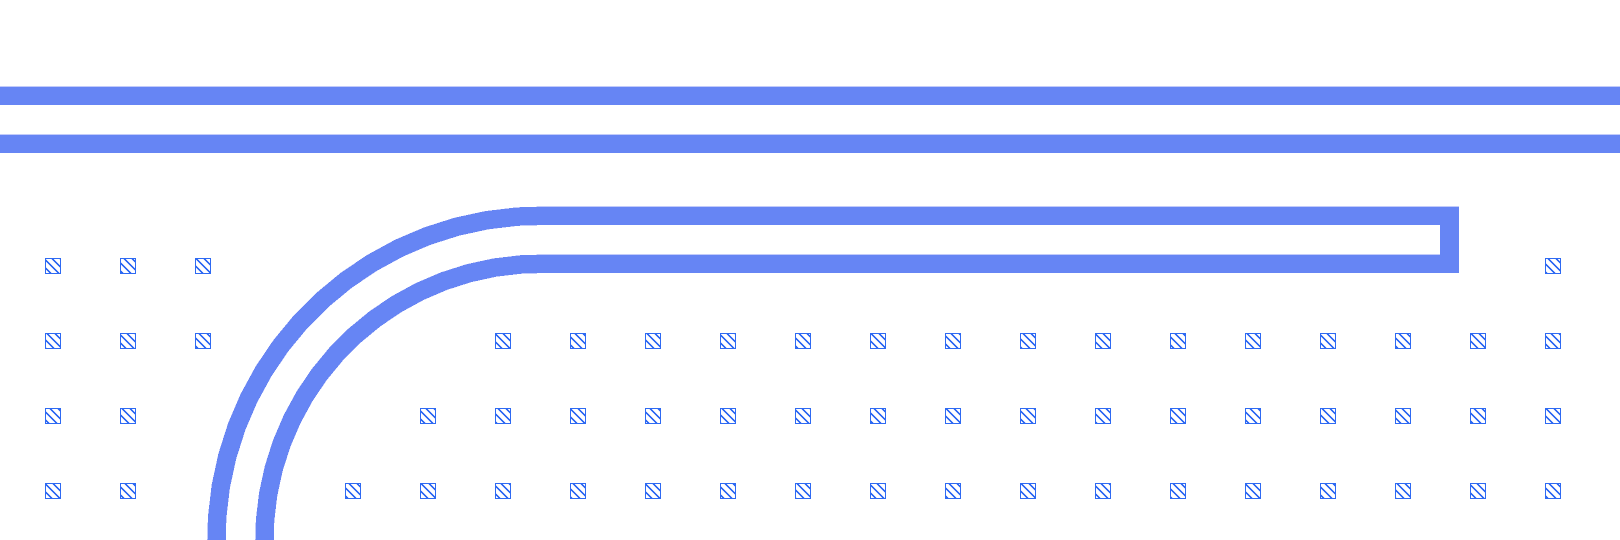

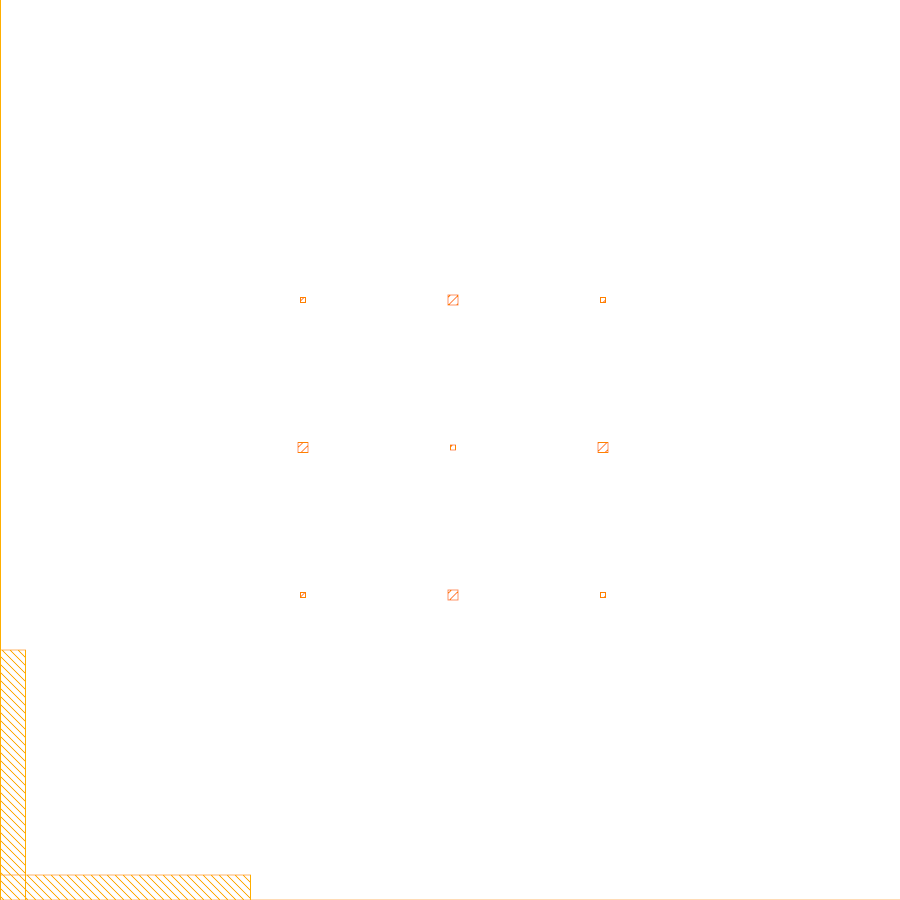

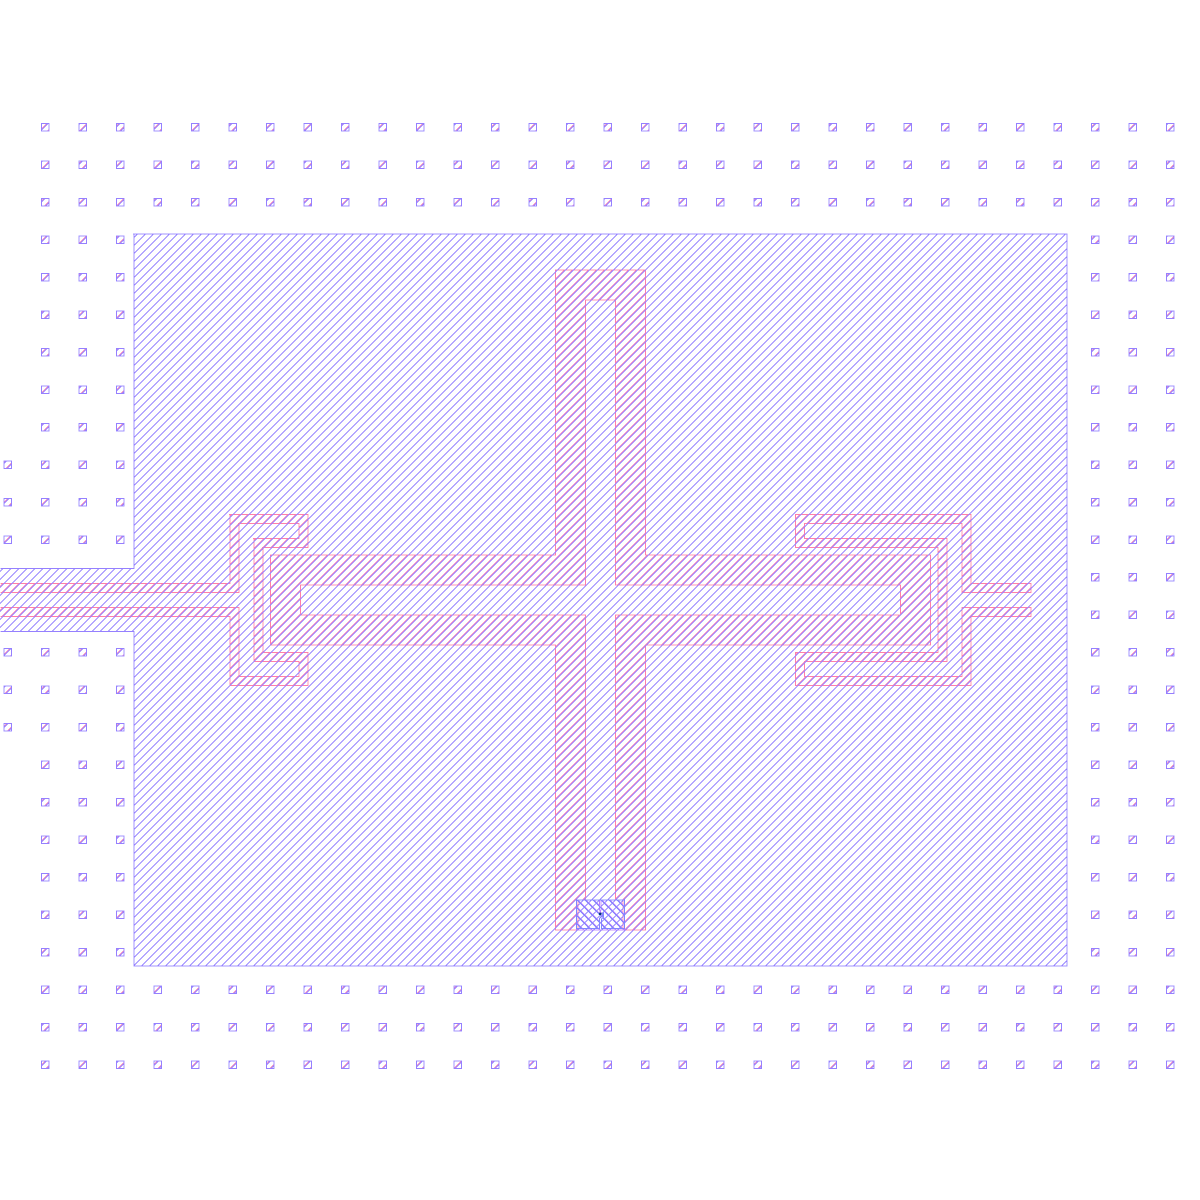

In [18]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
cx, cy = d.data["routes"]["R1"]["to"]["near"]               # centre of the coupled section (after centring)
show_snapshot(d, OUT / "xmon_cap_sim.png", size=(1600, 1600), width=640)
show_snapshot(d, OUT / "xmon_cap_sim_q1.png", box=(qx - 400, qy - 300, qx + 400, qy + 300), size=(1200, 900), width=450)
show_snapshot(d, OUT / "xmon_cap_sim_jj.png", box=(qx - 40, qy - 260, qx + 40, qy - 180), width=300)
show_snapshot(d, OUT / "xmon_cap_sim_coupler.png", box=(cx - 280, cy - 140, cx + 260, cy + 40), size=(1620, 540), width=560)
show_snapshot(d, OUT / "xmon_cap_sim_frame.png", box=(-1450, -2550, -550, -1650), size=(900, 900), width=300)
snap_file(Path("build") / "xmon_cap_sim_fab.oas", OUT / "xmon_cap_sim_fab_q1.png",
          box=(qx - 400, qy - 400, qx + 400, qy + 400), size=(1200, 1200), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | the `TransmonCross` with the source's claws (95 µm `bus_01` left open), the launchpads, the 3.7 mm readout with its open coupled section 40 µm from the line at the source's position, the Q3D sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; launchpads moved to the die edges (outer etch 100 µm), so the line is 2.7 mm longer; content centred (moved ≈ 214 µm down); sapphire; the PDK nominal trilayer junction (the source has none); the PDK cheese band in the mask |
| **substituted** | meander + `OpenToGround` as one open hanger route; the line as a straight route |
| **PDK design warnings** | none expected (the `pdk_claw` check now reads `claw_length: 95` as 95 µm) |
| **FEM** | a Q3D C-matrix and an eigenmode / EPR job exported to `build/jobs/xmon_cap_sim_Q1R1_*`, not solved here |